# Experiment 10: Cross-Modal Retrieval (Text ↔ Image)

**Course:** Multimodal Data Analysis (BAI-417)
**Name:** Sneha Roychowdhury
**Section:** ECE-AI (2)

---

## Aim
To perform cross-modal retrieval, where queries in one modality (text) retrieve data in another modality (images), and the reverse (images retrieve text).

## Theory

### 1. What is cross-modal retrieval?
In ordinary (uni-modal) retrieval the query and the results are of the same type, for example text searching text. In **cross-modal retrieval** they are of different types:
- **Text → Image:** typing *"small red circle on the left"* returns matching pictures (Google Images, stock photo search, e-commerce visual search).
- **Image → Text:** giving a picture returns the captions or descriptions that fit it (image captioning by retrieval, product tagging).

### 2. The heterogeneity gap
An image is described by pixel based features (colour histograms, edge orientations), and text by word based features (TF-IDF). These vectors have **different lengths and different meanings for each axis**, so a text vector cannot be compared with an image vector directly. Even if the lengths happened to match, dimension 5 of an image vector and dimension 5 of a text vector describe unrelated things, and their distance would mean nothing.

The standard solution is to learn **two mappings into one shared (common) embedding space**:

$$f_{img}: \mathbb{R}^{d_i} \rightarrow \mathbb{R}^{k}, \qquad f_{txt}: \mathbb{R}^{d_t} \rightarrow \mathbb{R}^{k}$$

trained so that an image and its matching caption land **close together**. Retrieval then becomes nearest-neighbour search with cosine similarity in that space.

### 3. Feature extraction
- **Image:** an HSV **colour histogram** (captures colour) and a **HOG** (Histogram of Oriented Gradients) descriptor, which records edge directions in small cells and therefore captures shape, size and position. The two are standardised and reduced with **PCA**.
- **Text:** **TF-IDF** vectors of the captions (unigrams and bigrams).

### 4. Method A: Canonical Correlation Analysis (CCA)
CCA is the classical method for cross-modal retrieval. It finds projection directions $a$ and $b$ that maximise the correlation between the projected image and text features of matching pairs:

$$\max_{a,b}\ \rho = \frac{a^\top \Sigma_{it}\, b}{\sqrt{a^\top \Sigma_{ii}\, a}\ \sqrt{b^\top \Sigma_{tt}\, b}}$$

Further pairs of directions are found under the constraint that they are uncorrelated with the earlier ones, which gives a $k$-dimensional shared space. CCA is linear, needs no negative examples, and has a closed-form style solution.

### 5. Method B: Two-tower contrastive learning (the idea behind CLIP)
Each modality has its own encoder (here a linear layer) followed by L2 normalisation. For a batch of $B$ matching pairs, the similarity matrix is $S_{jk} = \frac{u_j^{img}\cdot u_k^{txt}}{\tau}$, where $\tau$ is a temperature. The **symmetric InfoNCE loss** treats the true pair as the correct "class" among all $B$ candidates, in both directions:

$$\mathcal{L} = \frac{1}{2B}\sum_{j=1}^{B}\left[-\log\frac{e^{S_{jj}}}{\sum_k e^{S_{jk}}} \;-\; \log\frac{e^{S_{jj}}}{\sum_k e^{S_{kj}}}\right]$$

This pulls matching pairs together and pushes non-matching pairs apart. OpenAI's **CLIP** uses exactly this loss with deep encoders (a Vision Transformer and a text Transformer) trained on 400 million image-text pairs. Here it is implemented **from scratch in NumPy**, with the gradients derived by hand and verified numerically.

### 6. Evaluation
For every query, all items of the other modality in the test set are ranked by cosine similarity. A result counts as **relevant** if it has the same **shape and colour** as the query.

| Metric | Meaning |
|---|---|
| mAP | Mean Average Precision over all queries (rewards relevant items ranked high) |
| P@5 | Fraction of the top 5 results that are relevant |
| R@1 | Fraction of queries whose top result is relevant |
| Attribute accuracy | Whether the top result has the right shape, colour, size and position, checked separately |

## Algorithm
1. Generate an image-caption dataset (800 images with varied, paraphrased captions) and export it as a folder of PNG images and a CSV file.
2. Split into train and test sets, keeping two shape-colour combinations completely out of training.
3. Extract image features (HSV histogram + HOG → PCA) and text features (TF-IDF).
4. Show why the raw features cannot be compared across modalities.
5. Learn a shared space with CCA.
6. Learn a shared space with a two-tower contrastive model (NumPy, symmetric InfoNCE).
7. Retrieve images from text queries and text from image queries; evaluate both directions.
8. Analyse what each method captures, test unseen combinations and free-form queries, and visualise the shared space.
9. (Optional, needs internet) Compare with pretrained CLIP used zero-shot.

## Step 0: Import libraries
Everything used in Steps 1 to 10 comes preinstalled on Colab and needs no internet. Only the optional Step 11 downloads a pretrained model.

In [1]:
import os, math, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from IPython.display import display

SEED = 7
random.seed(SEED); np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 80)
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## Step 1: Create and export the dataset
The notebook generates its own image-caption dataset, so it runs anywhere and every attribute of every image is known exactly.

- **Images (96×96):** one object on a textured background, with five attributes:
  - **shape:** circle, square, triangle, star, cross
  - **colour:** red, green, blue, yellow, purple
  - **size:** small, large
  - **position:** left, centre, right
  - plus random **jitter** in exact position, size, rotation and shade
- **Captions:** written from templates with **synonyms and different word orders**, so the text model cannot rely on one fixed phrase. Some captions also leave out the size or the position, as people often do. Examples: *"a big crimson disc towards the left"*, *"there is a violet five-pointed star in the middle"*.

**Exported files:** `xmodal_data/images/*.png` and `xmodal_data/captions.csv`.

In [2]:
SHAPES  = ["circle", "square", "triangle", "star", "cross"]
COLOURS = {"red": (40, 40, 220), "green": (60, 170, 50), "blue": (210, 90, 30),
           "yellow": (30, 210, 235), "purple": (170, 50, 150)}            # BGR
SIZES, POSITIONS = ["small", "large"], ["left", "centre", "right"]

SYN = {
    "red": ["red", "crimson", "scarlet"], "green": ["green", "emerald"], "blue": ["blue", "azure"],
    "yellow": ["yellow", "golden"], "purple": ["purple", "violet"],
    "circle": ["circle", "disc", "round shape"], "square": ["square", "box"],
    "triangle": ["triangle", "three-sided shape"], "star": ["star", "five-pointed star"],
    "cross": ["cross", "plus sign"],
    "small": ["small", "tiny", "little"], "large": ["large", "big", "huge"],
    "left": ["on the left", "towards the left", "at the left side"],
    "centre": ["in the centre", "in the middle", "at the centre"],
    "right": ["on the right", "towards the right", "at the right side"],
}
TEMPLATES = ["a {size} {colour} {shape} {pos}", "{pos}, a {size} {colour} {shape}",
             "there is a {colour} {shape} {pos}", "a {size} {shape} in {colour} {pos}",
             "{size} {colour} {shape}", "picture of a {colour} {shape}, {size}, {pos}"]

def caption(shape, colour, size, pos, rng):
    pick = lambda k: rng.choice(SYN[k])
    return rng.choice(TEMPLATES).format(shape=pick(shape), colour=pick(colour), size=pick(size), pos=pick(pos))

def draw(shape, colour, size, pos, rng, H=96):
    img = np.full((H, H, 3), rng.integers(200, 236), np.uint8)
    img = np.clip(img + rng.normal(0, 7, img.shape), 0, 255).astype(np.uint8)       # textured background
    for _ in range(4):                                                                # faint grey distractor lines
        p1, p2 = tuple(int(v) for v in rng.integers(0, H, 2)), tuple(int(v) for v in rng.integers(0, H, 2))
        cv2.line(img, p1, p2, (175, 175, 175), 1)
    r = int((11 if size == "small" else 24) * rng.uniform(0.9, 1.1))
    cx = {"left": 27, "centre": 48, "right": 69}[pos] + int(rng.integers(-3, 4))
    cy = 48 + int(rng.integers(-6, 7))
    col = tuple(int(np.clip(c * rng.uniform(0.85, 1.1), 0, 255)) for c in COLOURS[colour])
    ang = rng.uniform(-0.3, 0.3)
    if shape == "circle":
        cv2.circle(img, (cx, cy), r, col, -1, cv2.LINE_AA)
    elif shape == "square":
        box = cv2.boxPoints(((cx, cy), (1.6 * r, 1.6 * r), np.degrees(ang)))
        cv2.fillPoly(img, [box.astype(np.int32)], col, cv2.LINE_AA)
    elif shape == "triangle":
        pts = [(cx + r * math.cos(ang + a), cy + r * math.sin(ang + a)) for a in (-math.pi / 2, math.pi / 6, 5 * math.pi / 6)]
        cv2.fillPoly(img, [np.array(pts, np.int32)], col, cv2.LINE_AA)
    elif shape == "star":
        pts = [(cx + (r if k % 2 == 0 else 0.45 * r) * math.cos(ang - math.pi / 2 + k * math.pi / 5),
                cy + (r if k % 2 == 0 else 0.45 * r) * math.sin(ang - math.pi / 2 + k * math.pi / 5)) for k in range(10)]
        cv2.fillPoly(img, [np.array(pts, np.int32)], col, cv2.LINE_AA)
    elif shape == "cross":
        t = max(3, r // 3)
        cv2.rectangle(img, (cx - r, cy - t), (cx + r, cy + t), col, -1)
        cv2.rectangle(img, (cx - t, cy - r), (cx + t, cy + r), col, -1)
    return img

rng = np.random.default_rng(SEED)
os.makedirs("xmodal_data/images", exist_ok=True)
rows, k = [], 0
for shape in SHAPES:
    for colour in COLOURS:
        for _ in range(32):                                   # 25 combinations x 32 = 800 images
            size, pos = rng.choice(SIZES), rng.choice(POSITIONS)
            fname = f"img_{k:04d}.png"
            cv2.imwrite(f"xmodal_data/images/{fname}", draw(shape, colour, size, pos, rng))
            rows.append({"image_file": fname, "caption": caption(shape, colour, size, pos, rng),
                         "shape": shape, "colour": colour, "size": size, "position": pos})
            k += 1
data = pd.DataFrame(rows)

# Train/test split. Two combinations never appear in training (to test generalisation).
HELD_OUT = [("star", "purple"), ("triangle", "yellow")]
held = data.apply(lambda r: (r["shape"], r["colour"]) in HELD_OUT, axis=1)
test_rest = data[~held].sample(136, random_state=SEED).index
data["split"] = "train"
data.loc[held | data.index.isin(test_rest), "split"] = "test"
data.to_csv("xmodal_data/captions.csv", index=False)

print(f"Exported {len(data)} images to xmodal_data/images/ and captions to xmodal_data/captions.csv")
print(data.split.value_counts().to_string())

Exported 800 images to xmodal_data/images/ and captions to xmodal_data/captions.csv
split
train    600
test     200


## Step 2: Load the exported dataset

In [3]:
data = pd.read_csv("xmodal_data/captions.csv")
images = np.array([cv2.cvtColor(cv2.imread(f"xmodal_data/images/{f}"), cv2.COLOR_BGR2RGB) for f in data.image_file])
train = data[data.split == "train"].reset_index(drop=True)
test = data[data.split == "test"].reset_index(drop=True)
tr_idx, te_idx = np.where(data.split == "train")[0], np.where(data.split == "test")[0]

print("Image array:", images.shape)
print(f"Train pairs: {len(train)} | Test pairs: {len(test)} | Unique captions: {data.caption.nunique()}")
data.sample(8, random_state=1)[["image_file", "caption", "shape", "colour", "size", "position", "split"]]

Image array: (800, 96, 96, 3)
Train pairs: 600 | Test pairs: 200 | Unique captions: 767


,image_file,caption,shape,colour,size,position,split
8,img_0008.png,"towards the right, a little red round shape",circle,red,small,right,train
510,img_0510.png,"towards the right, a little crimson five-pointed star",star,red,small,right,train
175,img_0175.png,small red box,square,red,small,right,train
735,img_0735.png,"picture of a blue plus sign, little, on the right",cross,blue,small,right,train
242,img_0242.png,a large azure square at the centre,square,blue,large,centre,test
764,img_0764.png,a large cross in golden in the centre,cross,yellow,large,centre,train
540,img_0540.png,a large star in green towards the left,star,green,large,left,train
430,img_0430.png,"picture of a yellow three-sided shape, big, on the left",triangle,yellow,large,left,test


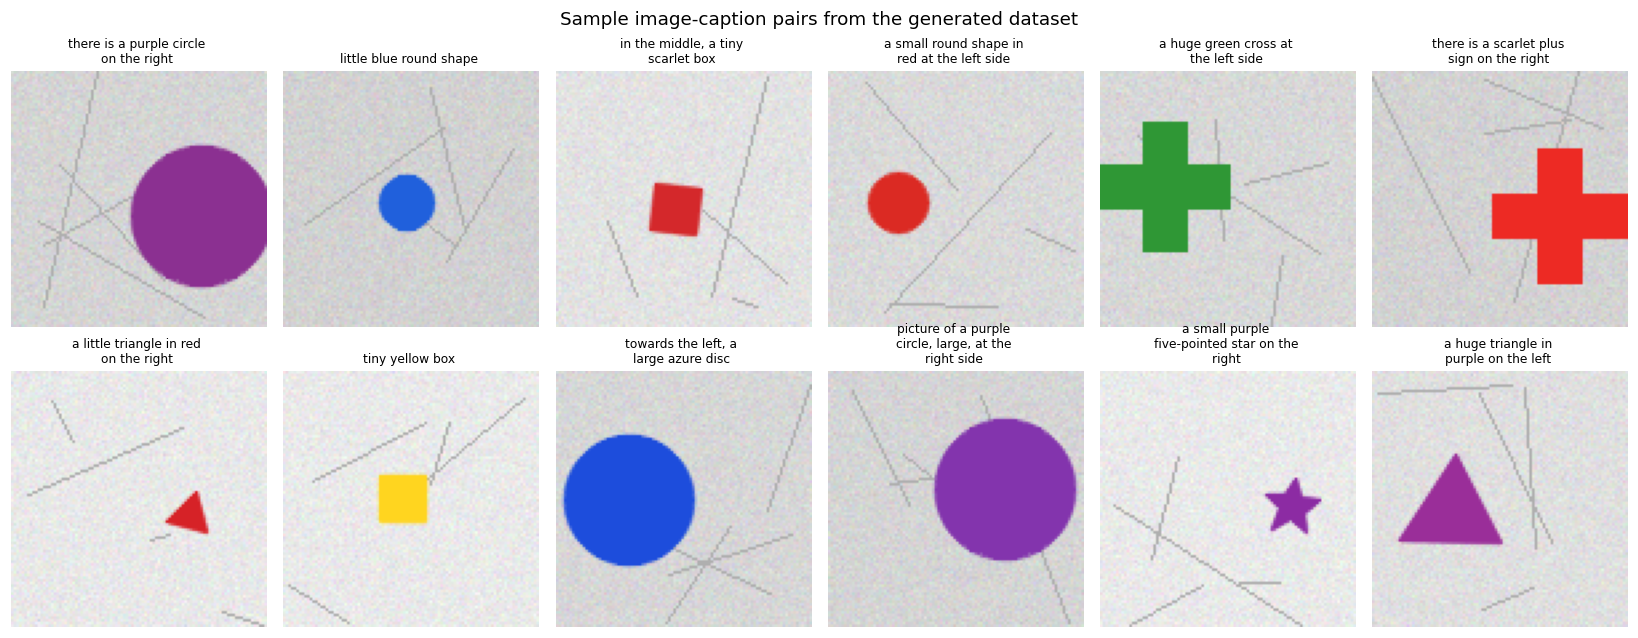

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, i in zip(axes.ravel(), np.random.default_rng(3).choice(len(data), 12, replace=False)):
    ax.imshow(images[i]); ax.axis("off")
    words, line, out = data.caption[i].split(), "", []
    for w in words:
        if len(line) + len(w) > 24: out.append(line); line = ""
        line += w + " "
    out.append(line)
    ax.set_title("\n".join(out), fontsize=8)
plt.suptitle("Sample image-caption pairs from the generated dataset")
plt.tight_layout(); plt.show()

## Step 3: Feature extraction
### 3.1 Image features
A good image feature should describe **what the object is** and not the background. So the image is first **segmented**, and then colour and shape are described separately.

1. **Segmentation:** in HSV space the background and the distractor lines are grey (low saturation) while the object is coloured (high saturation). Thresholding saturation and applying a morphological opening gives a clean **object mask**.
2. **Colour descriptor (20 values):** an 18-bin hue histogram of the object pixels only, plus their mean saturation and brightness.
3. **Geometry descriptor (13 values)** from the object's outer contour:
   - size: area
   - position: centroid x and y
   - shape: circularity $4\pi A/P^2$, solidity (area divided by convex hull area), extent (area divided by bounding box area), aspect ratio and number of polygon corners
   - **Hu moments:** 7 values that do not change with position, scale or rotation, log-scaled
4. **HOG of the mask (900 values → PCA 40):** a Histogram of Oriented Gradients records edge directions cell by cell, so it adds a detailed outline of the shape and where it sits in the frame.

Each block is standardised, and the large HOG block is reduced with PCA first, so it cannot drown out the small colour block. PCA and the scalers are fitted on the training set only.

In [5]:
def object_mask(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    m = ((hsv[..., 1] > 90) & (hsv[..., 2] > 50)).astype(np.uint8) * 255
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

def colour_feat(img, mask):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[mask > 0]
    h = np.histogram(hsv[:, 0], bins=18, range=(0, 180))[0].astype(float)
    return np.r_[h / max(h.sum(), 1), hsv[:, 1].mean() / 255, hsv[:, 2].mean() / 255]

def geometry_feat(mask):
    cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c = max(cs, key=cv2.contourArea)
    A, P = cv2.contourArea(c), cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    M = cv2.moments(c)
    hu = cv2.HuMoments(M).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-12)
    return np.r_[A / mask.size, M["m10"] / M["m00"] / mask.shape[1], M["m01"] / M["m00"] / mask.shape[0],
                 4 * math.pi * A / P ** 2, A / cv2.contourArea(cv2.convexHull(c)), A / (w * h), w / h,
                 len(cv2.approxPolyDP(c, 0.04 * P, True)), hu[:5]]

def hog_feat(mask, visualize=False):
    return hog(cv2.resize(mask, (48, 48)), orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), visualize=visualize)

masks = np.array([object_mask(im) for im in images])
F_col = np.array([colour_feat(im, m) for im, m in zip(images, masks)])
F_geo = np.array([geometry_feat(m) for m in masks])
F_hog = np.array([hog_feat(m) for m in masks])
print("Colour:", F_col.shape, "| Geometry:", F_geo.shape, "| HOG:", F_hog.shape)

# HOG: standardise -> PCA(40) -> standardise again, all fitted on training images only
sc_hog = StandardScaler().fit(F_hog[tr_idx])
pca_hog = PCA(n_components=40, random_state=SEED).fit(sc_hog.transform(F_hog[tr_idx]))
H = pca_hog.transform(sc_hog.transform(F_hog))
print(f"HOG PCA keeps {pca_hog.explained_variance_ratio_.sum():.1%} of the HOG variance")

blocks = [F_col, F_geo, H]
scalers = [StandardScaler().fit(B[tr_idx]) for B in blocks]
X_img = np.hstack([sc.transform(B) for sc, B in zip(scalers, blocks)])
print(f"Final image feature: {X_img.shape}  (20 colour + 13 geometry + 40 HOG-PCA)")

Colour: (800, 20) | Geometry: (800, 13) | HOG: (800, 900)
HOG PCA keeps 72.9% of the HOG variance
Final image feature: (800, 73)  (20 colour + 13 geometry + 40 HOG-PCA)


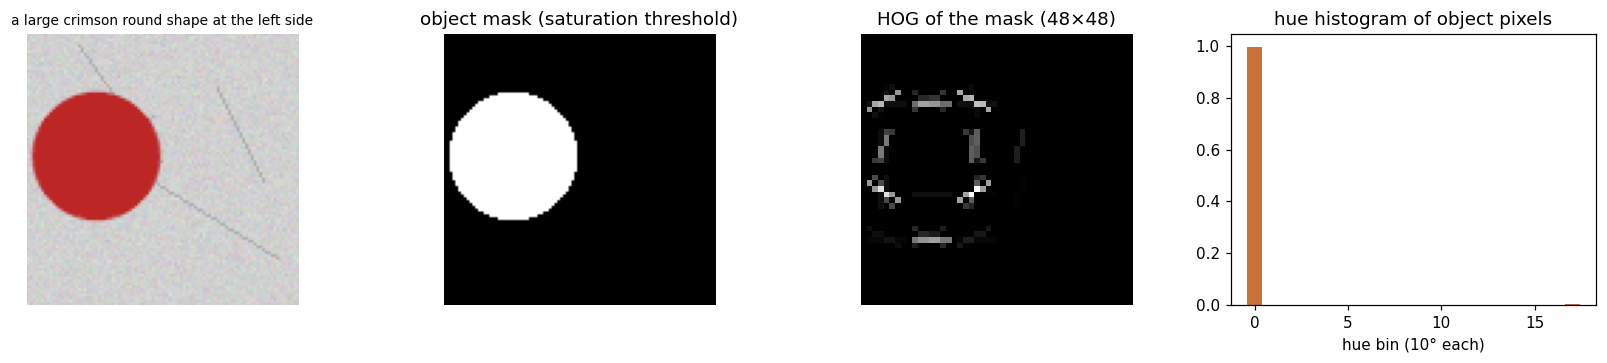

,circularity,solidity,corners
shape,,,
circle,0.91,0.99,7.92
cross,0.42,0.68,5.88
square,0.75,0.96,4.00
star,0.44,0.69,7.99
triangle,0.62,0.94,3.26


In [6]:
i = 5
_, hog_img = hog_feat(masks[i], visualize=True)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
axes[0].imshow(images[i]); axes[0].set_title(data.caption[i], fontsize=9)
axes[1].imshow(masks[i], cmap="gray"); axes[1].set_title("object mask (saturation threshold)")
axes[2].imshow(hog_img, cmap="gray"); axes[2].set_title("HOG of the mask (48×48)")
for a in axes[:3]: a.axis("off")
axes[3].bar(range(18), F_col[i, :18], color="#c9733a"); axes[3].set_title("hue histogram of object pixels")
axes[3].set_xlabel("hue bin (10° each)")
plt.tight_layout(); plt.show()

# Geometry descriptors separate the shapes well even before any learning
geo = pd.DataFrame(F_geo[:, [3, 4, 7]], columns=["circularity", "solidity", "corners"])
geo["shape"] = data["shape"].values
geo.groupby("shape").mean().round(2)

### 3.2 Text features
TF-IDF over single words (unigrams), fitted on training captions only. Word pairs (bigrams) were tried first, but they produce combinations like *azure box* that tie the text features to particular shape-colour pairs and make the models overfit, so single words generalise better here.

In [7]:
tfidf = TfidfVectorizer(min_df=2, token_pattern=r"(?u)\b[a-z]+\b")
tfidf.fit(data.caption[tr_idx])
X_txt = tfidf.transform(data.caption).toarray()
print("Text feature:", X_txt.shape)
print("Vocabulary:", " ".join(tfidf.get_feature_names_out()))

Text feature: (800, 47)
Vocabulary: a at azure big blue box centre circle crimson cross disc emerald five golden green huge in is large left little middle of on picture plus pointed purple red right round scarlet shape side sided sign small square star the there three tiny towards triangle violet yellow


## Step 4: Why the raw features cannot be compared
A text query becomes a vector whose length is the TF-IDF vocabulary size, while every image is a vector of length 73. Nearest-neighbour search between them is not defined. The cell below shows the error, and then a "cheat" where both are cut to the same length, which runs but gives meaningless (chance level) results. This is the **heterogeneity gap** that a shared space is meant to close.

In [8]:
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=5).fit(X_img[te_idx])
try:
    nn.kneighbors(X_txt[te_idx][:1])
except ValueError as e:
    print("ValueError:", str(e)[:120], "...")

# Forcing equal length by truncation runs, but the axes mean different things
D_TRUNC = min(X_img.shape[1], X_txt.shape[1])
fake = normalize(X_txt[te_idx][:, :D_TRUNC]) @ normalize(X_img[te_idx][:, :D_TRUNC]).T
print(f"\nTruncated to {D_TRUNC} dims: the similarity matrix can be computed, but see its quality in Step 7.")

ValueError: X has 47 features, but NearestNeighbors is expecting 73 features as input. ...

Truncated to 47 dims: the similarity matrix can be computed, but see its quality in Step 7.


## Step 5: Method A, Canonical Correlation Analysis
CCA is fitted on the 600 training pairs. Both modalities are projected into a 16-dimensional shared space, then L2-normalised so that the dot product equals cosine similarity.

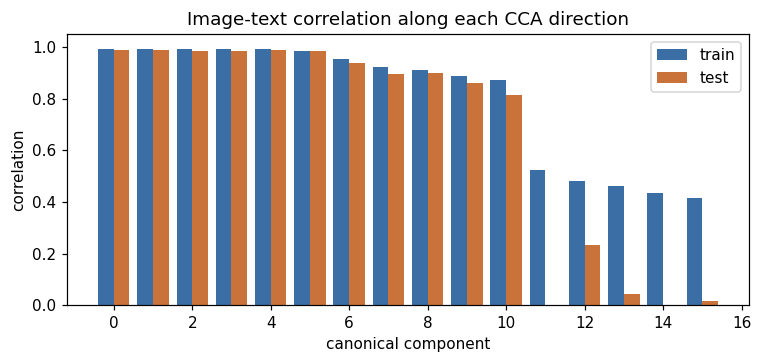

In [9]:
K_CCA = 16
cca = CCA(n_components=K_CCA, max_iter=2000)
cca.fit(X_img[tr_idx], X_txt[tr_idx])
Z_img_cca, Z_txt_cca = cca.transform(X_img, X_txt)
Z_img_cca, Z_txt_cca = normalize(Z_img_cca), normalize(Z_txt_cca)

# Correlation achieved in each canonical direction (train vs test)
raw_i, raw_t = cca.transform(X_img, X_txt)
corr = lambda idx: [np.corrcoef(raw_i[idx, j], raw_t[idx, j])[0, 1] for j in range(K_CCA)]
plt.figure(figsize=(8, 3.2))
plt.bar(np.arange(K_CCA) - 0.2, corr(tr_idx), 0.4, label="train", color="#3b6ea5")
plt.bar(np.arange(K_CCA) + 0.2, corr(te_idx), 0.4, label="test", color="#c9733a")
plt.xlabel("canonical component"); plt.ylabel("correlation"); plt.ylim(0, 1.05)
plt.title("Image-text correlation along each CCA direction"); plt.legend(); plt.show()

## Step 6: Method B, two-tower contrastive model (NumPy, from scratch)
### 6.1 Model and hand-derived gradients
- Encoders: $z^{img} = X^{img}W_i$, $z^{txt} = X^{txt}W_t$, then L2 normalisation $u = z/\lVert z\rVert$.
- Logits: $S = U^{img}(U^{txt})^\top/\tau$ with $\tau = 0.1$.
- Gradient of the symmetric loss with respect to $S$: $\frac{1}{2B}\left[(\text{softmax}_{row}(S) - I) + (\text{softmax}_{col}(S) - I)\right]$.
- Through the similarity: $\partial L/\partial U^{img} = G\,U^{txt}/\tau$ and $\partial L/\partial U^{txt} = G^\top U^{img}/\tau$.
- Through the normalisation: $\partial L/\partial z = \left(g - u\,(g\cdot u)\right)/\lVert z\rVert$.
- Finally $\partial L/\partial W = X^\top\,\partial L/\partial z$.

In [10]:
def softmax(a, axis):
    a = a - a.max(axis=axis, keepdims=True)
    e = np.exp(a)
    return e / e.sum(axis=axis, keepdims=True)

def loss_and_grads(Wi, Wt, Xi, Xt, tau=0.1):
    zi, zt = Xi @ Wi, Xt @ Wt
    ni, nt = np.linalg.norm(zi, axis=1, keepdims=True), np.linalg.norm(zt, axis=1, keepdims=True)
    ui, ut = zi / ni, zt / nt
    S = ui @ ut.T / tau
    B = len(S)
    Pr, Pc = softmax(S, 1), softmax(S, 0)
    loss = -0.5 * (np.log(np.diag(Pr)).mean() + np.log(np.diag(Pc)).mean())
    G = ((Pr - np.eye(B)) + (Pc - np.eye(B))) / (2 * B)          # dL/dS
    gui, gut = G @ ut / tau, G.T @ ui / tau                       # dL/du
    gzi = (gui - ui * (gui * ui).sum(1, keepdims=True)) / ni      # through L2 norm
    gzt = (gut - ut * (gut * ut).sum(1, keepdims=True)) / nt
    return loss, Xi.T @ gzi, Xt.T @ gzt

# Numerical gradient check on a tiny random problem
r = np.random.default_rng(0)
Xi_, Xt_, Wi_, Wt_ = r.normal(size=(6, 5)), r.normal(size=(6, 4)), r.normal(size=(5, 3)), r.normal(size=(4, 3))
_, gWi, gWt = loss_and_grads(Wi_, Wt_, Xi_, Xt_)
num = np.zeros_like(Wi_); eps = 1e-6
for a in range(Wi_.shape[0]):
    for b in range(Wi_.shape[1]):
        Wp, Wm = Wi_.copy(), Wi_.copy(); Wp[a, b] += eps; Wm[a, b] -= eps
        num[a, b] = (loss_and_grads(Wp, Wt_, Xi_, Xt_)[0] - loss_and_grads(Wm, Wt_, Xi_, Xt_)[0]) / (2 * eps)
print("Max difference, analytic vs numerical gradient:", np.abs(num - gWi).max())

Max difference, analytic vs numerical gradient: 2.204874394173828e-09


### 6.2 Training with mini-batches and the Adam optimiser
Training uses only the 600 training pairs. A random 10% of training pairs is held aside as a validation set to watch for overfitting.

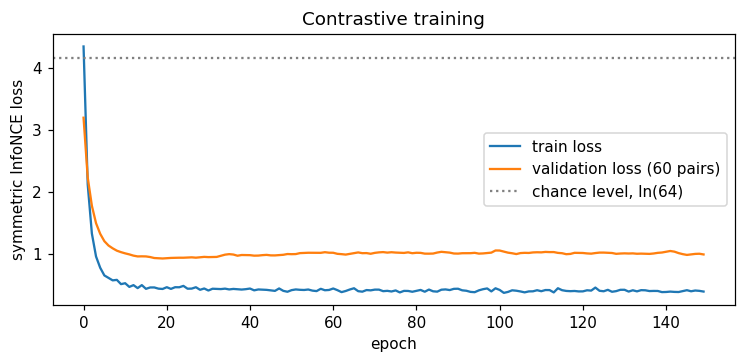

Final train loss 0.392 | validation loss 0.989 (validation uses a batch of 60, chance = 4.09)


In [11]:
K, TAU, EPOCHS, BATCH, LR, WD = 32, 0.1, 150, 64, 0.01, 1e-4
rng_t = np.random.default_rng(SEED)
perm = rng_t.permutation(tr_idx)
val_ids, fit_ids = perm[:60], perm[60:]

Wi = rng_t.normal(0, 1 / np.sqrt(X_img.shape[1]), (X_img.shape[1], K))
Wt = rng_t.normal(0, 1 / np.sqrt(X_txt.shape[1]), (X_txt.shape[1], K))
state = {n: [np.zeros_like(W), np.zeros_like(W)] for n, W in [("i", Wi), ("t", Wt)]}

def adam(W, g, st, t, lr=LR, b1=0.9, b2=0.999):
    st[0] = b1 * st[0] + (1 - b1) * g
    st[1] = b2 * st[1] + (1 - b2) * g * g
    mh, vh = st[0] / (1 - b1 ** t), st[1] / (1 - b2 ** t)
    return W - lr * (mh / (np.sqrt(vh) + 1e-8) + WD * W)

hist, step = [], 0
for ep in range(EPOCHS):
    order = rng_t.permutation(fit_ids)
    losses = []
    for s in range(0, len(order) - BATCH + 1, BATCH):
        b = order[s:s + BATCH]; step += 1
        L, gWi, gWt = loss_and_grads(Wi, Wt, X_img[b], X_txt[b], TAU)
        Wi, Wt = adam(Wi, gWi, state["i"], step), adam(Wt, gWt, state["t"], step)
        losses.append(L)
    val_L = loss_and_grads(Wi, Wt, X_img[val_ids], X_txt[val_ids], TAU)[0]
    hist.append((np.mean(losses), val_L))

hist = np.array(hist)
plt.figure(figsize=(8, 3.2))
plt.plot(hist[:, 0], label="train loss"); plt.plot(hist[:, 1], label="validation loss (60 pairs)")
plt.axhline(np.log(BATCH), color="grey", ls=":", label=f"chance level, ln({BATCH})")
plt.xlabel("epoch"); plt.ylabel("symmetric InfoNCE loss"); plt.title("Contrastive training")
plt.legend(); plt.show()
print(f"Final train loss {hist[-1, 0]:.3f} | validation loss {hist[-1, 1]:.3f} (validation uses a batch of 60, chance = {np.log(60):.2f})")

Z_img_ctr, Z_txt_ctr = normalize(X_img @ Wi), normalize(X_txt @ Wt)

## Step 7: Retrieval and evaluation in both directions
All 200 test captions are matched against all 200 test images. Relevance means the same shape and colour; on average each query has about 8 relevant items out of 200, so a random ranking scores a mAP of about 0.04.

In [12]:
shp, colr = test["shape"].to_numpy(str), test["colour"].to_numpy(str)
same_sc = (shp[:, None] == shp[None]) & (colr[:, None] == colr[None])    # [query x item] relevance

def average_precision(scores, rel):
    order = np.argsort(-scores)
    hits = rel[order]
    if hits.sum() == 0:
        return 0.0
    return (np.cumsum(hits) / np.arange(1, len(hits) + 1))[hits].mean()

def evaluate(S):
    # S: similarity matrix [test captions x test images]
    out = {}
    for name, M in [("Text→Image", S), ("Image→Text", S.T)]:
        ap = [average_precision(M[q], same_sc[q]) for q in range(len(M))]
        top5 = np.argsort(-M, axis=1)[:, :5]
        out[(name, "mAP")] = np.mean(ap)
        out[(name, "P@5")] = np.mean([same_sc[q, top5[q]].mean() for q in range(len(M))])
        out[(name, "R@1")] = np.mean([same_sc[q, top5[q, 0]] for q in range(len(M))])
    return out

rng_e = np.random.default_rng(1)
sims = {
    "Random ranking": rng_e.random((len(test), len(test))),
    "Raw features (truncated)": fake,
    "CCA (k=16)": Z_txt_cca[te_idx] @ Z_img_cca[te_idx].T,
    "Contrastive two-tower (k=32)": Z_txt_ctr[te_idx] @ Z_img_ctr[te_idx].T,
}
results = pd.DataFrame({m: evaluate(S) for m, S in sims.items()}).T
results.columns = pd.MultiIndex.from_tuples(results.columns)
results.round(3)

Text→Image               Image→Text             
                                    mAP    P@5    R@1        mAP    P@5   R@1
Random ranking                    0.094  0.071  0.060      0.095  0.065  0.09
Raw features (truncated)          0.092  0.050  0.025      0.098  0.048  0.05
CCA (k=16)                        0.712  0.715  0.980      0.703  0.712  0.96
Contrastive two-tower (k=32)      0.701  0.726  0.990      0.705  0.714  0.99

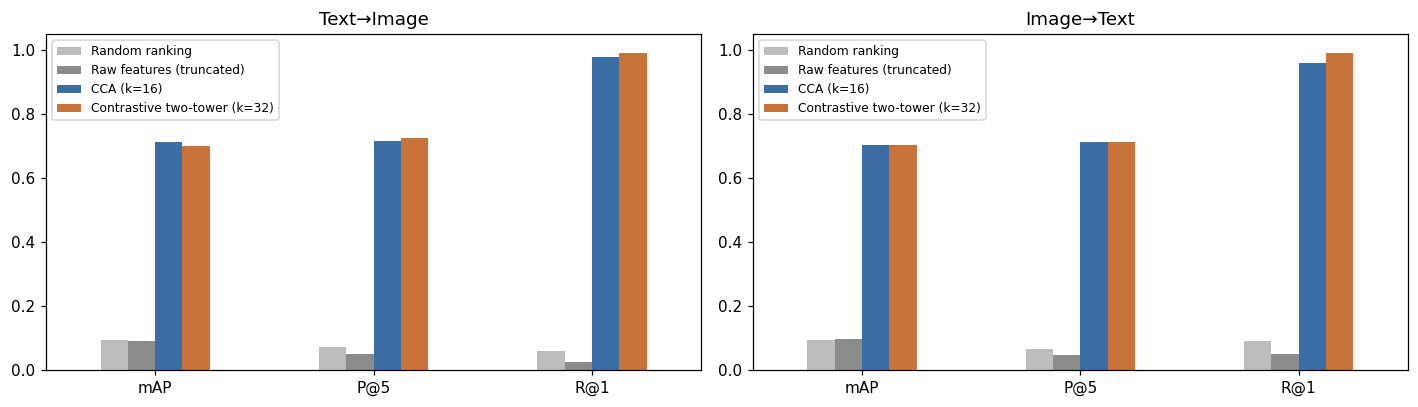

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
cols = ["#bdbdbd", "#8c8c8c", "#3b6ea5", "#c9733a"]
for ax, direction in zip(axes, ["Text→Image", "Image→Text"]):
    results[direction].T.plot(kind="bar", ax=ax, color=cols, rot=0)
    ax.set_ylim(0, 1.05); ax.set_title(direction); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.1 Text → Image: example queries
Captions from the test set are used as queries. A green border means the image has the right shape and colour; red means it does not.

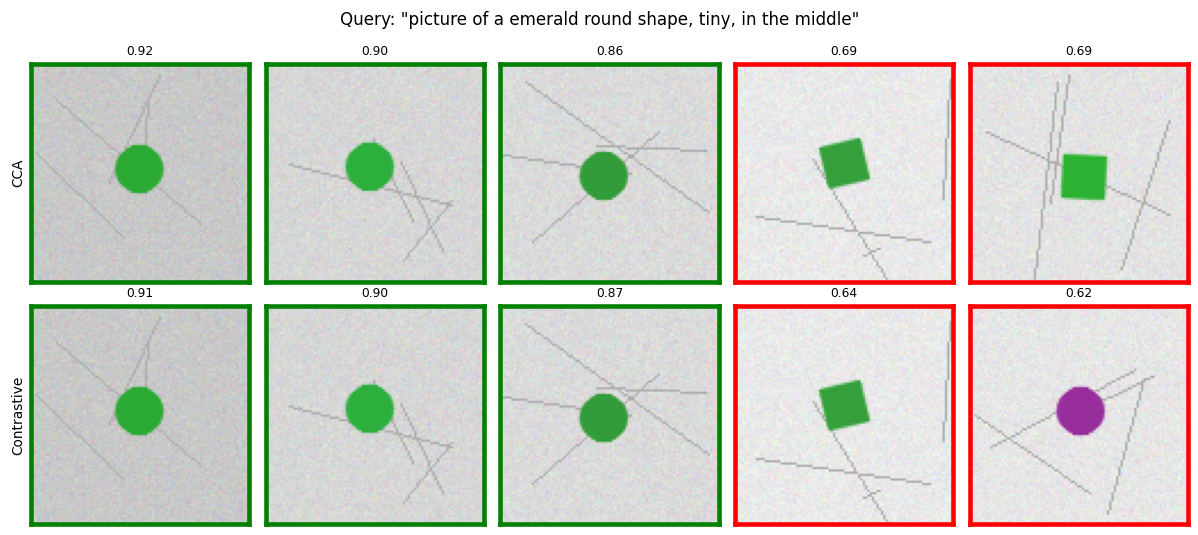

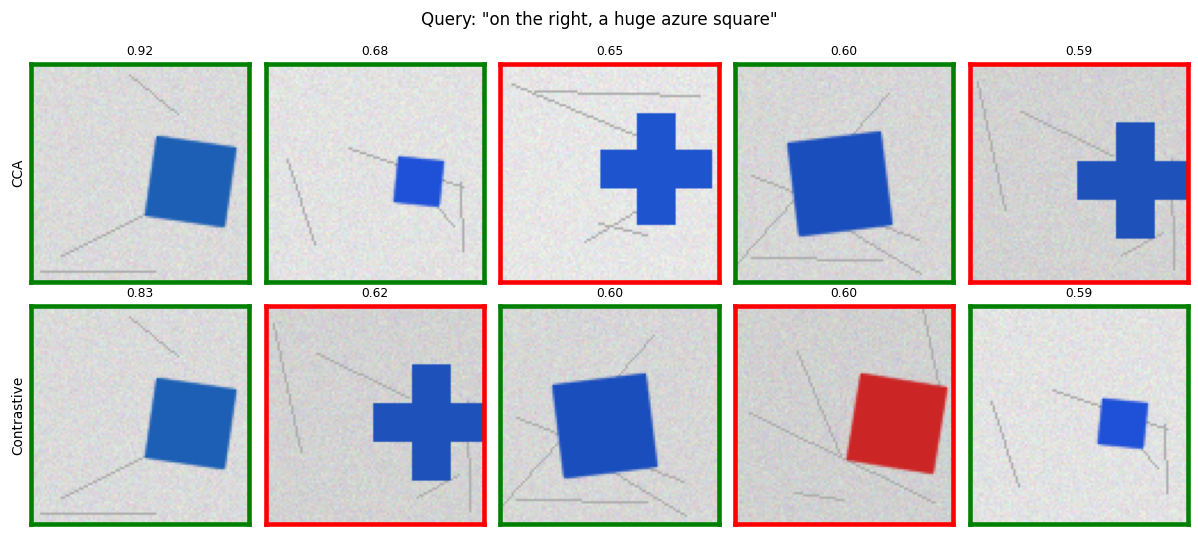

In [14]:
def show_text_query(query_vec_by_method, query_text, k=5, truth=None):
    fig, axes = plt.subplots(len(query_vec_by_method), k, figsize=(2.2 * k, 2.5 * len(query_vec_by_method)))
    for row, (mname, (qv, Zi)) in enumerate(query_vec_by_method.items()):
        s = Zi[te_idx] @ qv
        for col, j in enumerate(np.argsort(-s)[:k]):
            ax = axes[row, col]
            ax.imshow(images[te_idx[j]]); ax.set_xticks([]); ax.set_yticks([])
            if truth is not None:
                ok = test["shape"][j] == truth[0] and test["colour"][j] == truth[1]
                for sp in ax.spines.values(): sp.set_color("green" if ok else "red"); sp.set_linewidth(3)
            ax.set_title(f"{s[j]:.2f}", fontsize=8)
            if col == 0: ax.set_ylabel(mname, fontsize=9)
    plt.suptitle(f'Query: "{query_text}"', fontsize=11)
    plt.tight_layout(); plt.show()

for q in [3, 40]:
    tv = X_txt[te_idx[q]]
    show_text_query({"CCA": (normalize(cca.transform(X_img[:1], tv[None])[1])[0], Z_img_cca),
                     "Contrastive": (normalize((tv @ Wt)[None])[0], Z_img_ctr)},
                    test.caption[q], truth=(test["shape"][q], test["colour"][q]))

### 7.2 Image → Text: example queries
A test image is the query; the five closest test captions are listed.

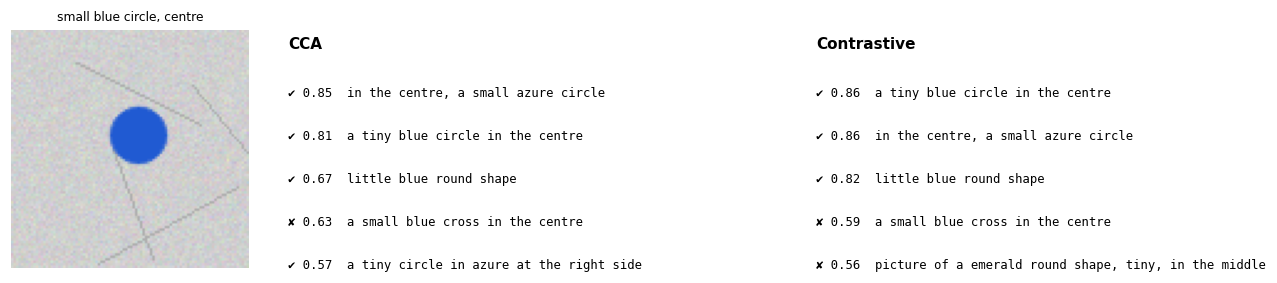

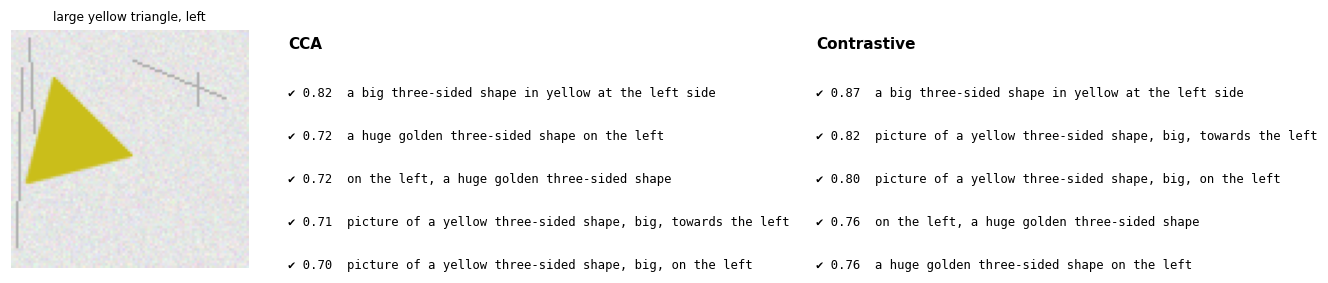

In [15]:
for q in [10, 77]:
    fig = plt.figure(figsize=(12, 2.6))
    ax = fig.add_axes([0, 0, 0.18, 1]); ax.imshow(images[te_idx[q]]); ax.axis("off")
    ax.set_title(f"{test['size'][q]} {test['colour'][q]} {test['shape'][q]}, {test['position'][q]}", fontsize=8)
    for c, (mname, Zi, Zt) in enumerate([("CCA", Z_img_cca, Z_txt_cca), ("Contrastive", Z_img_ctr, Z_txt_ctr)]):
        s = Zt[te_idx] @ Zi[te_idx[q]]
        lines = [f"{'✔' if same_sc[q, j] else '✘'} {s[j]:.2f}  {test.caption[j]}" for j in np.argsort(-s)[:5]]
        fig.text(0.21 + 0.40 * c, 0.85, mname, fontsize=10, fontweight="bold")
        for r_, l in enumerate(lines):
            fig.text(0.21 + 0.40 * c, 0.68 - r_ * 0.15, l, fontsize=8, family="monospace")
    plt.show()

## Step 8: What does each method actually capture?
### 8.1 Attribute accuracy of the top result
For every text query, the top-ranked image is checked attribute by attribute. Chance levels are 20% for shape and colour, 50% for size and about 33% for position. (Size and position are only scored when the caption mentions them.)

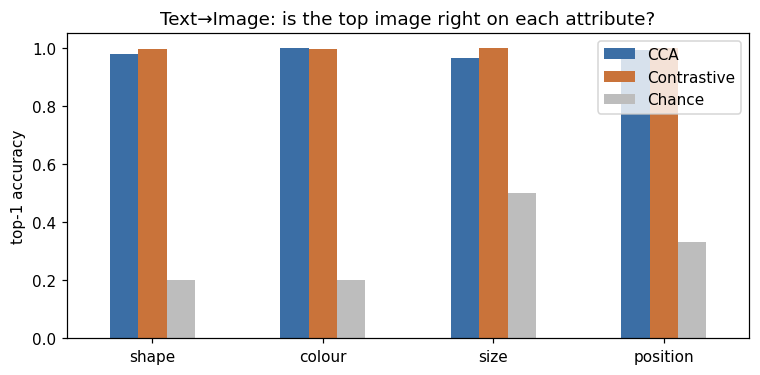

,CCA,Contrastive,Chance
shape,0.980,0.995,0.200
colour,1.000,0.995,0.200
size,0.966,1.000,0.500
position,0.994,1.000,0.333


In [16]:
mentions = lambda cap, attr: any(w in cap for w in SYN[attr])

def attribute_accuracy(Zt, Zi):
    S = Zt[te_idx] @ Zi[te_idx].T
    top = np.argmax(S, axis=1)
    acc = {}
    for a in ["shape", "colour", "size", "position"]:
        ok = [test[a][top[q]] == test[a][q] for q in range(len(test))
              if a in ("shape", "colour") or mentions(test.caption[q], test[a][q])]
        acc[a] = np.mean(ok)
    return acc

attr = pd.DataFrame({"CCA": attribute_accuracy(Z_txt_cca, Z_img_cca),
                     "Contrastive": attribute_accuracy(Z_txt_ctr, Z_img_ctr),
                     "Chance": {"shape": 0.2, "colour": 0.2, "size": 0.5, "position": 1 / 3}})
ax = attr.plot(kind="bar", figsize=(8, 3.6), color=["#3b6ea5", "#c9733a", "#bdbdbd"], rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("top-1 accuracy"); ax.set_title("Text→Image: is the top image right on each attribute?")
plt.show()
attr.round(3)

### 8.2 Unseen combinations
*Purple star* and *yellow triangle* never appeared in training. The models have seen purple things and stars, yellow things and triangles, but never these pairs together. Can they combine what they learned?

Note: all 32 images of each unseen pair are in the test set, so their queries have 32 relevant items, while queries for seen pairs have about 6. mAP rises with the number of relevant items, so the two groups' mAP values **cannot be compared directly**. R@1 (is the top result right?) is the fair comparison.

In [17]:
held_mask = test.apply(lambda r: (r["shape"], r["colour"]) in HELD_OUT, axis=1).values
rows = []
for mname, (Zi, Zt) in {"CCA": (Z_img_cca, Z_txt_cca), "Contrastive": (Z_img_ctr, Z_txt_ctr)}.items():
    S = Zt[te_idx] @ Zi[te_idx].T
    for grp, m in [("seen combinations", ~held_mask), ("unseen combinations", held_mask)]:
        ap = [average_precision(S[q], same_sc[q]) for q in np.where(m)[0]]
        r1 = [same_sc[q, np.argmax(S[q])] for q in np.where(m)[0]]
        rows.append({"method": mname, "queries": grp, "n": int(m.sum()), "mAP": np.mean(ap), "R@1": np.mean(r1)})
pd.DataFrame(rows).set_index(["method", "queries"]).round(3)

n    mAP    R@1
method      queries                               
CCA         seen combinations    136  0.631  0.971
            unseen combinations   64  0.884  1.000
Contrastive seen combinations    136  0.613  0.985
            unseen combinations   64  0.890  1.000

### 8.3 Free-form text queries
New queries typed by a user, not taken from the dataset. Words the TF-IDF vocabulary has never seen are simply ignored, which is a real limitation of bag-of-words text features.

"a huge golden plus sign"  known words: ['a', 'huge', 'golden', 'plus', 'sign']  ignored: []


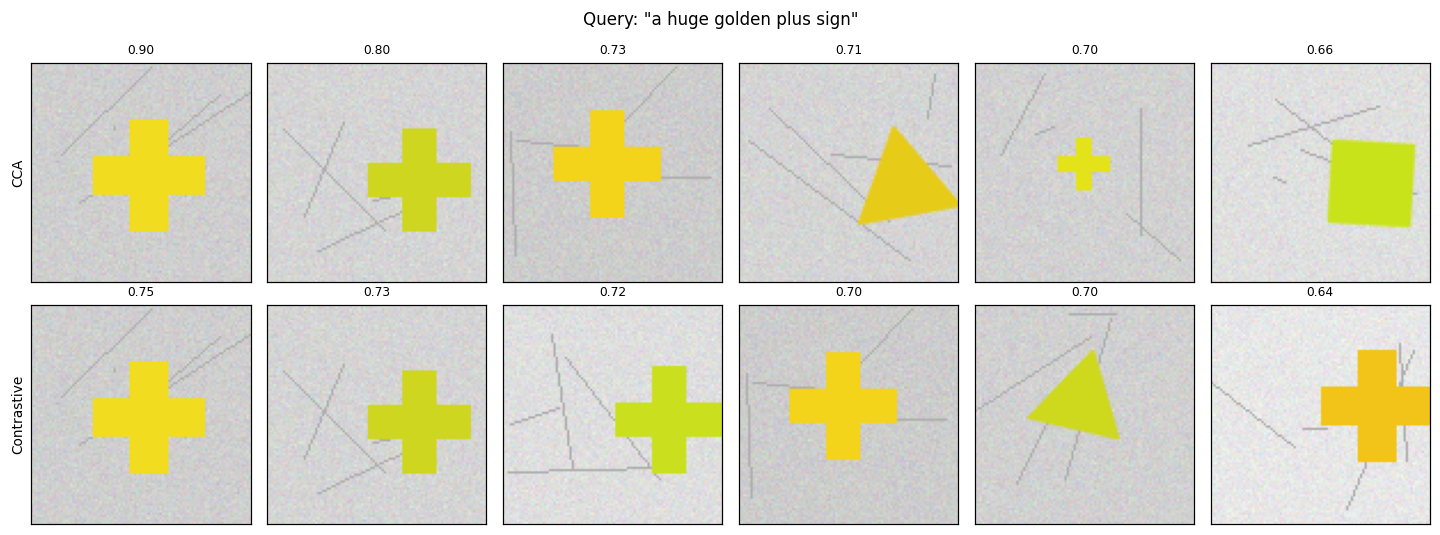

"tiny emerald box on the right"  known words: ['tiny', 'emerald', 'box', 'on', 'the', 'right']  ignored: []


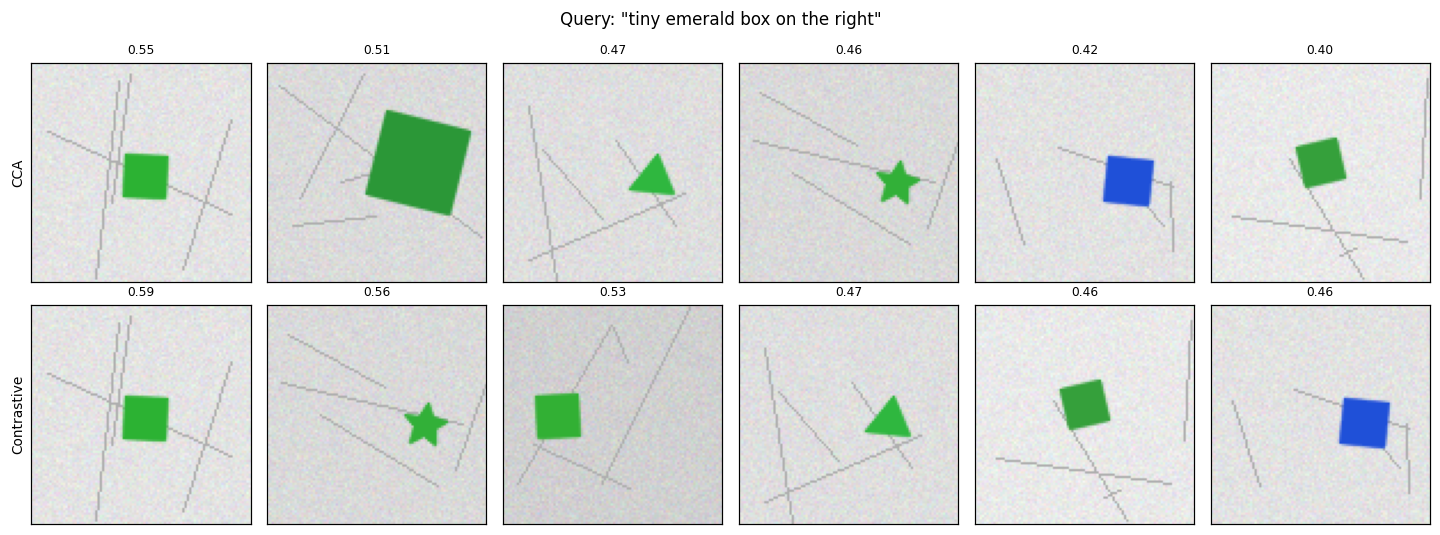

"a pink heart"  known words: ['a']  ignored: ['pink', 'heart']


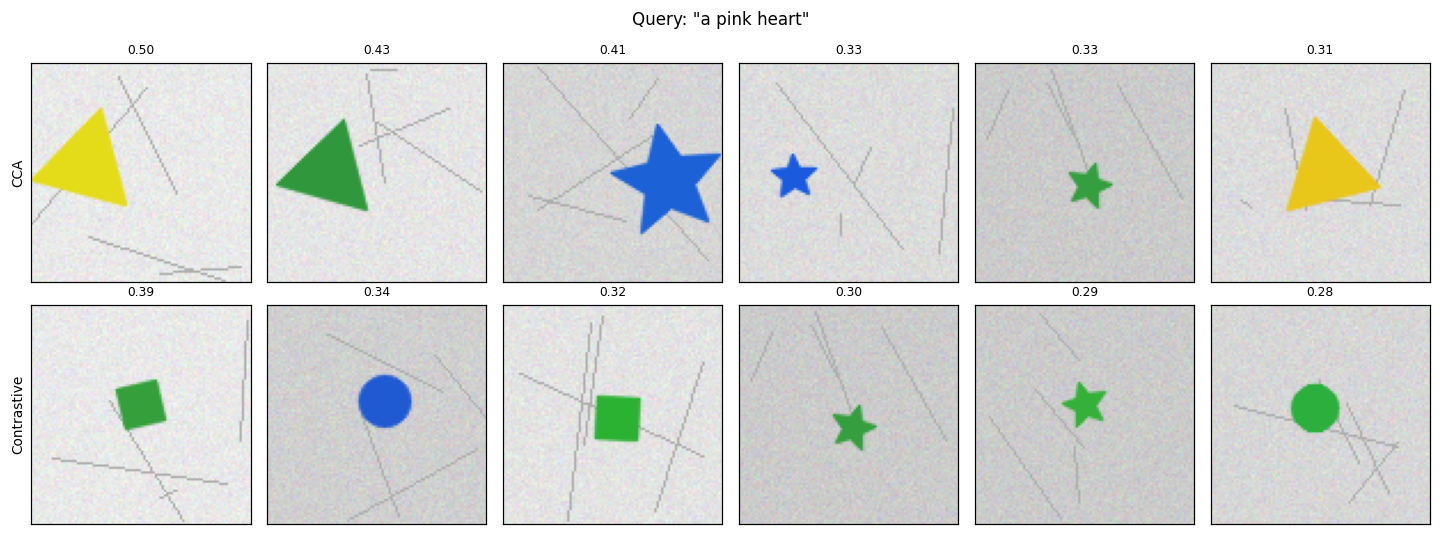

In [18]:
def free_query(text, k=6):
    v = tfidf.transform([text]).toarray()[0]
    known = [w for w in text.lower().split() if w in tfidf.vocabulary_]
    unknown = [w for w in text.lower().split() if w not in tfidf.vocabulary_]
    print(f'"{text}"  known words: {known}  ignored: {unknown}')
    show_text_query({"CCA": (normalize(cca.transform(X_img[:1], v[None])[1])[0], Z_img_cca),
                     "Contrastive": (normalize((v @ Wt)[None])[0], Z_img_ctr)}, text, k=k)

free_query("a huge golden plus sign")
free_query("tiny emerald box on the right")
free_query("a pink heart")

### 8.4 Visualising the shared space
Image and text embeddings of the test set are projected to 2D with PCA (fitted on both modalities together). Colour shows the object colour, ● marks images and ✕ marks captions. In a good shared space, the two modalities overlap rather than forming two separate islands.

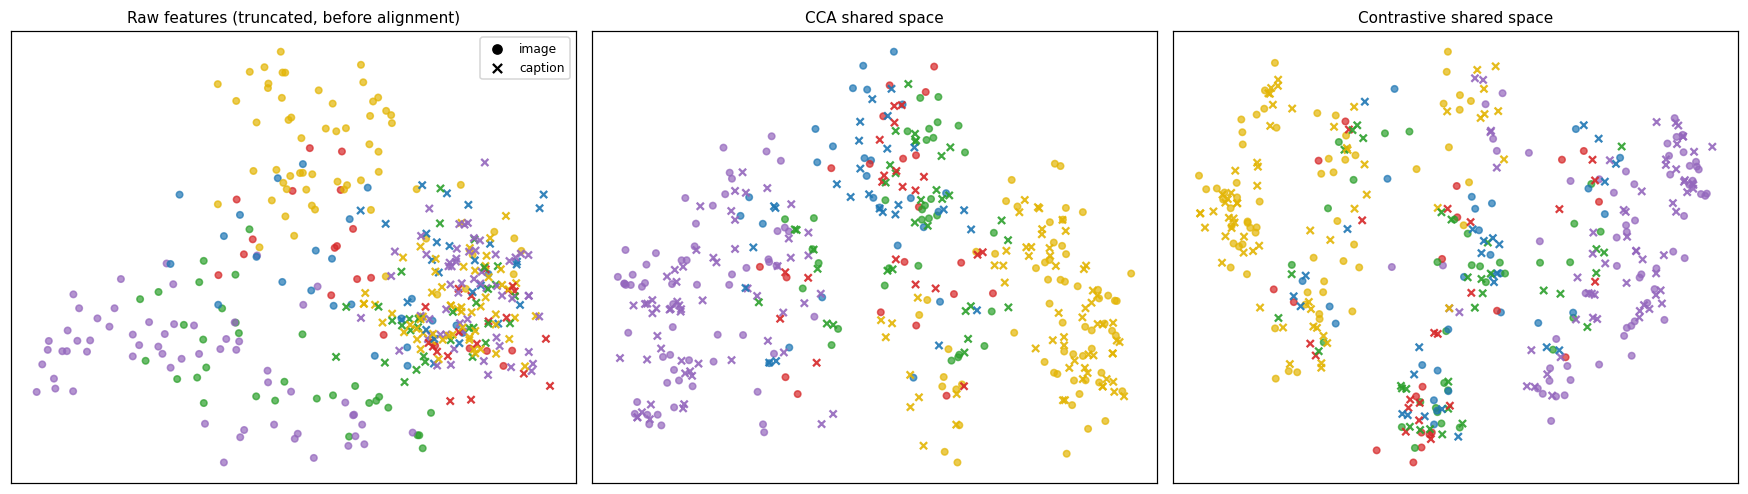

In [19]:
pal = {"red": "#d62728", "green": "#2ca02c", "blue": "#1f77b4", "yellow": "#e3b505", "purple": "#9467bd"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
spaces = [("Raw features (truncated, before alignment)", normalize(X_img[te_idx][:, :D_TRUNC]), normalize(X_txt[te_idx][:, :D_TRUNC])),
          ("CCA shared space", Z_img_cca[te_idx], Z_txt_cca[te_idx]),
          ("Contrastive shared space", Z_img_ctr[te_idx], Z_txt_ctr[te_idx])]
for ax, (title, A, B) in zip(axes, spaces):
    P = PCA(2, random_state=SEED).fit(np.vstack([A, B]))
    pa, pb = P.transform(A), P.transform(B)
    c = test.colour.map(pal)
    ax.scatter(pa[:, 0], pa[:, 1], c=c, marker="o", s=18, alpha=0.7)
    ax.scatter(pb[:, 0], pb[:, 1], c=c, marker="x", s=22, alpha=0.9)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0].scatter([], [], c="k", marker="o", label="image"); axes[0].scatter([], [], c="k", marker="x", label="caption")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.5 Modality gap: are matching pairs actually close?
For each test pair, the cosine similarity between an image and **its own caption** is compared with its similarity to **random other captions**. A good shared space separates the two distributions.

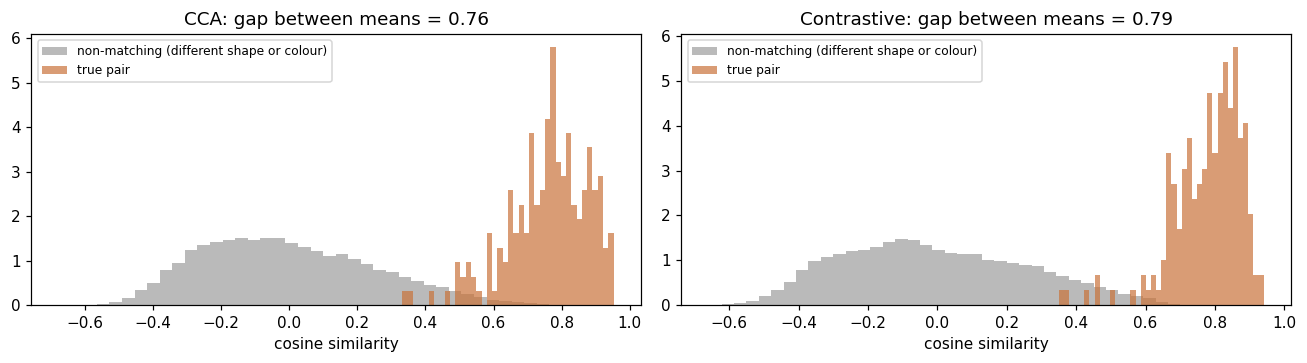

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, (mname, Zi, Zt) in zip(axes, [("CCA", Z_img_cca, Z_txt_cca), ("Contrastive", Z_img_ctr, Z_txt_ctr)]):
    S = Zt[te_idx] @ Zi[te_idx].T
    pos = np.diag(S); neg = S[~same_sc]
    ax.hist(neg, bins=40, alpha=0.6, density=True, label="non-matching (different shape or colour)", color="#8c8c8c")
    ax.hist(pos, bins=40, alpha=0.7, density=True, label="true pair", color="#c9733a")
    ax.set_title(f"{mname}: gap between means = {pos.mean() - neg.mean():.2f}")
    ax.set_xlabel("cosine similarity"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.6 Effect of the shared-space size
Test mAP (both directions averaged) as the number of dimensions $k$ changes. This is shown only to understand the method; $k$ was not chosen using the test set. CCA can produce at most 47 directions here (the size of the text vocabulary), so $k = 64$ is capped at 47.

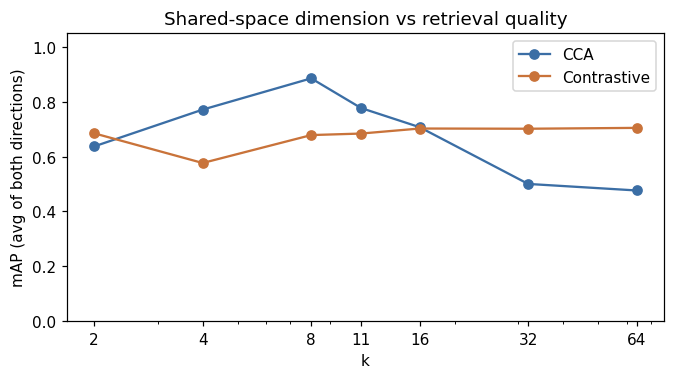

,CCA,Contrastive
k,,
2,0.637,0.685
4,0.771,0.577
8,0.885,0.679
11,0.777,0.684
16,0.707,0.703
32,0.500,0.702
64,0.477,0.705


In [21]:
def contrastive_fit(k, epochs=150, seed=SEED):
    rr = np.random.default_rng(seed)
    Wi_ = rr.normal(0, 1 / np.sqrt(X_img.shape[1]), (X_img.shape[1], k))
    Wt_ = rr.normal(0, 1 / np.sqrt(X_txt.shape[1]), (X_txt.shape[1], k))
    st = {n: [np.zeros_like(W), np.zeros_like(W)] for n, W in [("i", Wi_), ("t", Wt_)]}
    t = 0
    for _ in range(epochs):
        o = rr.permutation(fit_ids)
        for s in range(0, len(o) - BATCH + 1, BATCH):
            b = o[s:s + BATCH]; t += 1
            _, gi, gt = loss_and_grads(Wi_, Wt_, X_img[b], X_txt[b], TAU)
            Wi_, Wt_ = adam(Wi_, gi, st["i"], t), adam(Wt_, gt, st["t"], t)
    return normalize(X_img @ Wi_), normalize(X_txt @ Wt_)

import warnings
warnings.filterwarnings("ignore", message="y residual is constant")   # CCA cannot find more than 47 text directions

def both_map(Zi, Zt):
    r = evaluate(Zt[te_idx] @ Zi[te_idx].T)
    return (r[("Text→Image", "mAP")] + r[("Image→Text", "mAP")]) / 2

ks = [2, 4, 8, 11, 16, 32, 64]
k_rows = []
for k in ks:
    c = CCA(n_components=min(k, X_txt.shape[1]), max_iter=2000).fit(X_img[tr_idx], X_txt[tr_idx])
    a, b = c.transform(X_img, X_txt)
    k_rows.append({"k": k, "CCA": both_map(normalize(a), normalize(b)),
                   "Contrastive": both_map(*contrastive_fit(k))})
k_df = pd.DataFrame(k_rows).set_index("k")
ax = k_df.plot(marker="o", figsize=(7, 3.4), color=["#3b6ea5", "#c9733a"], logx=True)
ax.set_xticks(ks); ax.set_xticklabels(ks); ax.set_ylabel("mAP (avg of both directions)"); ax.set_ylim(0, 1.05)
ax.set_title("Shared-space dimension vs retrieval quality"); plt.show()
k_df.round(3)

## Step 9 (optional): Pretrained CLIP, zero-shot
This step downloads OpenAI's CLIP ViT-B/32 (about 600 MB) from Hugging Face, so it **needs an internet connection** (Colab has one). CLIP has never seen this dataset: it is used exactly as downloaded, with no training. If the download fails, the cell prints a message and the rest of the notebook is unaffected.

In [ ]:
try:
    import torch
    from PIL import Image
    from transformers import CLIPModel, CLIPProcessor
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
    proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    pil = [Image.fromarray(images[i]) for i in te_idx]
    with torch.no_grad():
        out = clip(**proc(text=list(test.caption), images=pil, return_tensors="pt", padding=True))
    Zi_clip = normalize(out.image_embeds.cpu().numpy())
    Zt_clip = normalize(out.text_embeds.cpu().numpy())
    clip_res = pd.DataFrame({"CLIP ViT-B/32 (zero-shot)": evaluate(Zt_clip @ Zi_clip.T)}).T
    clip_res.columns = pd.MultiIndex.from_tuples(clip_res.columns)
    display(pd.concat([results, clip_res]).round(3))

    top = np.argmax(Zt_clip @ Zi_clip.T, axis=1)
    print("CLIP top-1 attribute accuracy (Text→Image):",
          {a: round(np.mean([test[a][top[q]] == test[a][q] for q in range(len(test))
                              if a in ("shape", "colour") or mentions(test.caption[q], test[a][q])]), 3)
           for a in ["shape", "colour", "size", "position"]})
except Exception as e:
    print("CLIP step skipped (needs internet and the transformers library):", type(e).__name__, str(e)[:150])

## Results and Observations
1. **The heterogeneity gap is real.** Searching image vectors with a text vector fails outright, because the lengths differ (73 vs 47). Cutting both to the same length runs, but scores no better than a random ranking (text to image mAP 0.092 vs 0.094 for random). The raw-feature PCA plot shows images and captions as two separate clouds. A learned shared space is needed.
2. **Both methods work well.** In the shared space, the top result has the right shape and colour for 96% to 99% of queries in both directions (R@1 of 0.98 and 0.96 for CCA, 0.99 and 0.99 for the contrastive model). mAP is about 0.70 for both, against 0.09 for random. CCA and the contrastive model perform almost the same here, because both are linear maps on the same features.
3. **Why mAP is lower than R@1.** Relevance was defined as the same shape and colour, but the models also match size and position, as the query asks. Every "wrong" image in a top 5 shares the shape or the colour with the query, and about 80% of them also have the right size and position. For example, for *"on the right, a huge azure square"*, a large blue cross on the right ranks above a small blue square. So most "errors" are sensible near misses, and the strict metric understates quality.
4. **Attribute level accuracy.** The top image is correct on shape (98% CCA, 99.5% contrastive), colour (100%, 99.5%), size (97%, 100%) and position (99%, 100%), against chance levels of 20%, 20%, 50% and 33%. Synonyms (*crimson, scarlet* for red; *disc, round shape* for circle) are handled because they appear in training captions next to the same kinds of images.
5. **Unseen combinations.** For *purple star* and *yellow triangle*, never seen together in training, R@1 was **1.0 for both methods**. The models learned colour and shape as separate parts of the shared space and can combine them in new ways. This compositional generalisation comes naturally to linear models over separate colour and shape features. (Their higher mAP is not a fair comparison, as explained in Step 8.2.)
6. **Limits of the text side.** *"A huge golden plus sign"* and *"tiny emerald box on the right"* are new phrasings, built from known words, and they retrieve correctly. *"A pink heart"* contains no known colour or shape word. Only *"a"* is in the vocabulary, so the results are arbitrary, and the system has no way to say "no match". A pretrained text encoder (as in CLIP) would at least relate *pink* to *red* and *purple*.
7. **How many dimensions does the shared space need?** CCA's test correlation stays above 0.8 for the first 11 directions and collapses to near zero after that. Eleven is exactly the number of independent attribute choices in the data: 4 for shape, 4 for colour, 1 for size and 2 for position. In the sweep, CCA does best at $k = 8$ (mAP 0.885) and gets worse as more of the weak directions are added: 0.777 at $k = 11$, 0.707 at $k = 16$ and 0.50 at $k = 32$. CCA's cosine similarity gives every direction equal weight, so near-zero-correlation directions add noise. The main results used $k = 16$, fixed before testing. A rule that uses only training data, such as keeping directions with training correlation above 0.8, would give $k = 11$, which also beats $k = 16$. The contrastive model stays between 0.68 and 0.71 for every $k$ except 4, so it is much less sensitive to this choice.
8. **Contrastive training.** The hand-derived gradients match numerical gradients to about $2\times10^{-9}$. The loss fell from about 4.2 (chance) to 0.39 on training batches, and validation loss settled near 1.0 by about epoch 20, then crept up slightly. That is mild overfitting, so early stopping around epoch 20 would be enough. The similarity histograms show a wide separation between true pairs and non-matching pairs (gap between means 0.76 for CCA, 0.79 for contrastive).
9. **Role of feature engineering.** A first version used a whole-image colour histogram plus HOG of the grayscale image, with bigram text features. It reached only about 0.16 mAP: background and distractor lines dominated the image features, and bigrams overfit. Segmenting the object first and using single-word text features raised mAP to about 0.70. **The quality of the shared space depends heavily on the features fed into it.**
10. **Optional CLIP step.** CLIP needs no training on this dataset. When run in Colab, its zero-shot results appear in Step 9 for comparison with the two methods trained here.

## Conclusion
Cross-modal retrieval between text and images was implemented in both directions. Images were described by segmentation-based colour, geometry and HOG features, and captions by TF-IDF. Because these two feature spaces cannot be compared directly, two methods were used to learn a shared embedding space: Canonical Correlation Analysis, and a two-tower contrastive model trained with the symmetric InfoNCE loss (the objective behind CLIP), written from scratch in NumPy. Both placed matching images and captions close together, with the correct shape and colour at rank 1 for 96% to 99% of queries, against about 9% for a random ranking. They also retrieved shape-colour combinations never seen in training. The main limitations are on the text side (unknown words are ignored) and the dependence on handcrafted image features, which pretrained deep encoders such as CLIP address by learning both encoders from very large image-text collections.